# Phase 3 — Exploratory Data Analysis (EDA)
**Project:** Customer Churn & Retention Analytics Platform  
**Target:** Data Analyst / Business Intelligence Portfolio  
**Dataset:** Processed IBM Telco Customer Churn (7,043 Accounts)  

---

### Key Analytical Questions Addressed:
1. **Customer Demographics:** What is our customer distribution, and which demographic groups experience higher churn?
2. **Contract Type:** How stark is the churn rate difference between Month-to-Month contracts and Annual contracts?
3. **Tenure Lifecycle:** Does churn decrease with tenure, and what is the severity of the 1st-year onboarding cliff?
4. **Service Profiles:** Which specific internet and add-on services are correlated with elevated churn?
5. **Support Moat:** Do technical support and cybersecurity add-ons serve as retention anchors?
6. **Payment Methods:** How does manual payment via Electronic Check compare with automated methods?
7. **Revenue & Spend:** Are churned customers paying higher monthly bills than retained customers?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

df = pd.read_csv('../data/processed/customers_cleaned.csv')
print(f"Loaded analytical dataset with {df.shape[0]} rows and {df.shape[1]} columns.")
df.head(3)


Loaded analytical dataset with 7043 rows and 37 columns.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,SeniorCitizenLabel,ChurnFlag,TenureGroup,TenureCohort,MonthlyRevenue,AnnualRevenue,CustomerValueSegment,ContractCategory,PaymentCategory,ServiceCount,HasInternet,HasTechSupport,HasOnlineSecurity,RiskScore,ChurnRiskSegment,StrategicSegment
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,No,0,0-12 Months,New (0-1 yr),29.85,358.20,Low Value,Month-to-month,Manual,1,1,0,0,4,High Risk,Low/Med Value + High Risk (At-Risk Core)
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,No,0,25-48 Months,Established (2-4 yrs),56.95,683.40,Medium Value,One year,Manual,3,1,0,1,0,Low Risk,Low/Med Value + Low/Med Risk (Stable Core)
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,No,1,0-12 Months,New (0-1 yr),53.85,646.20,Medium Value,Month-to-month,Manual,3,1,0,1,3,Medium Risk,Low/Med Value + Low/Med Risk (Stable Core)


## 1. Overall Churn Distribution & Baseline KPI
Establish the company-wide baseline churn rate:
$$\text{Baseline Churn Rate} = \frac{\text{Churned Customers}}{\text{Total Customers}}$$


Total Customers:    7,043
Retained Customers: 5,174 (73.46%)
Churned Customers:  1,869 (26.54%)


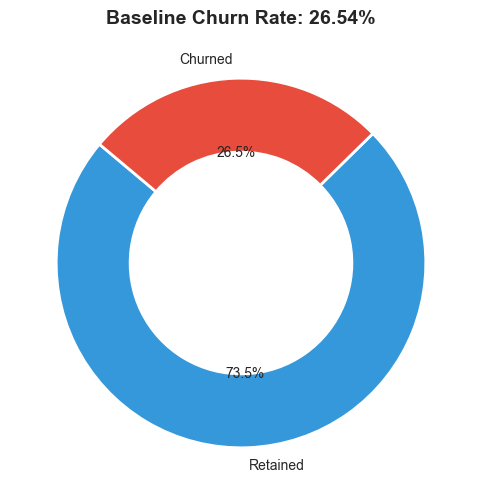

In [2]:
total_customers = len(df)
churn_count = df['ChurnFlag'].sum()
retained_count = total_customers - churn_count
churn_rate = (churn_count / total_customers) * 100

print(f"Total Customers:    {total_customers:,}")
print(f"Retained Customers: {retained_count:,} ({100 - churn_rate:.2f}%)")
print(f"Churned Customers:  {churn_count:,} ({churn_rate:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie([retained_count, churn_count], labels=['Retained', 'Churned'],
       autopct='%1.1f%%', colors=['#3498db', '#e74c3c'], startangle=140,
       wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
ax.set_title(f"Baseline Churn Rate: {churn_rate:.2f}%", fontsize=14, weight='bold')
plt.show()


## 2. Demographic Analysis: Age, Dependents, and Partners
Investigate whether demographic traits drive attrition.


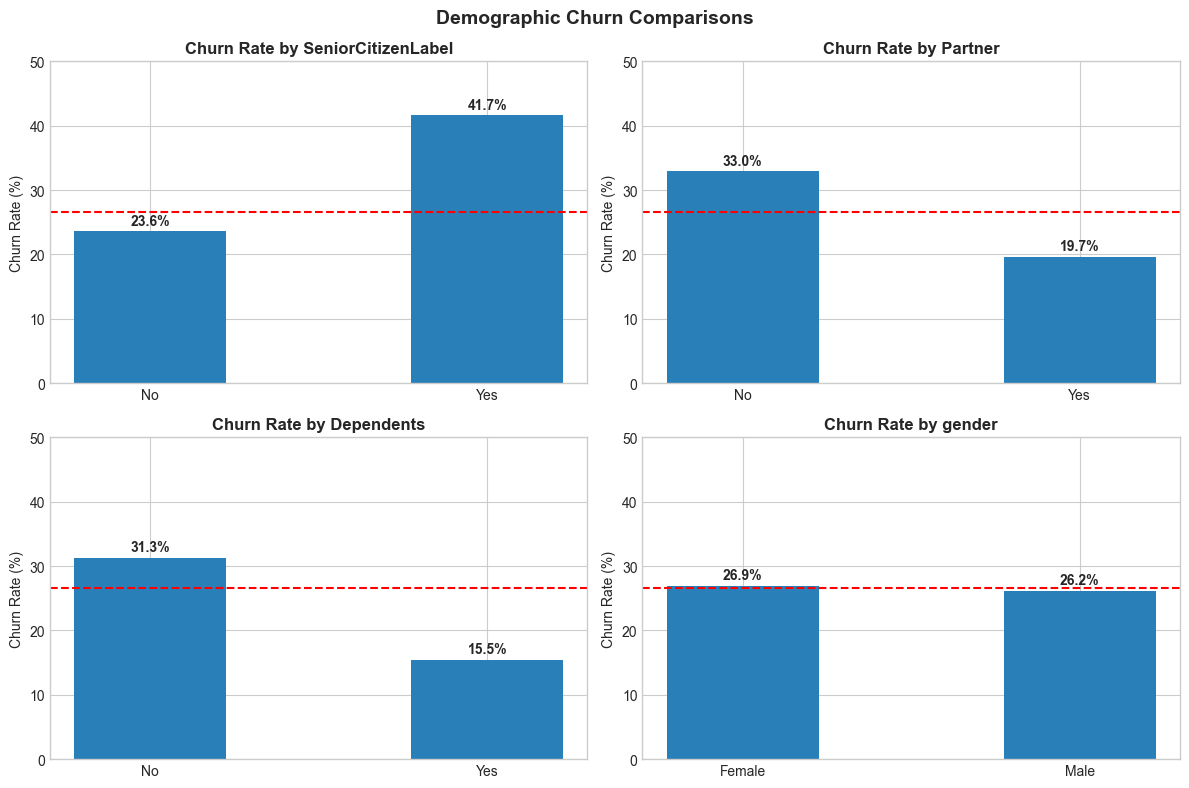

In [3]:
demo_cols = ['SeniorCitizenLabel', 'Partner', 'Dependents', 'gender']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), demo_cols):
    res = df.groupby(col).agg(
        Total=('customerID', 'count'),
        Churned=('ChurnFlag', 'sum'),
        ChurnRate=('ChurnFlag', lambda s: s.mean() * 100)
    )
    bars = ax.bar(res.index, res['ChurnRate'], color='#2980b9', width=0.45)
    ax.axhline(churn_rate, color='red', linestyle='--', label='Baseline Churn')
    ax.set_title(f'Churn Rate by {col}', fontsize=12, weight='bold')
    ax.set_ylabel('Churn Rate (%)')
    ax.set_ylim(0, 50)
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2., b.get_height() + 1, f"{b.get_height():.1f}%", ha='center', weight='bold')

plt.suptitle("Demographic Churn Comparisons", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()


**Demographic Findings:**
- **Senior Citizens:** Suffer a **41.7% churn rate** vs **23.6%** for younger demographics.
- **Dependents & Partners:** Customers with dependents churn at only **15.5%** vs **31.3%** for single accounts. Family accounts show much higher loyalty.
- **Gender:** Gender has virtually zero impact on churn (Male: 26.2%, Female: 26.9%).


## 3. Contract Type Analysis: The Single Biggest Driver
Analyze the relationship between commitment terms and attrition.


In [4]:
contract_stats = df.groupby('Contract').agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('ChurnFlag', 'sum'),
    Churn_Rate_Pct=('ChurnFlag', lambda s: s.mean() * 100),
    Monthly_Revenue=('MonthlyCharges', 'sum')
).reindex(['Month-to-month', 'One year', 'Two year'])
contract_stats


,Total_Customers,Churned_Customers,Churn_Rate_Pct,Monthly_Revenue
Contract,,,,
Month-to-month,3875,1655,42.71,257294.15
One year,1473,166,11.27,95816.60
Two year,1695,48,2.83,103005.85


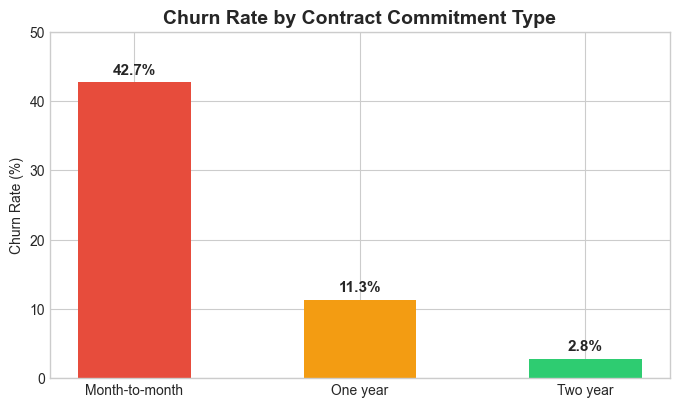

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(contract_stats.index, contract_stats['Churn_Rate_Pct'], color=['#e74c3c', '#f39c12', '#2ecc71'], width=0.5)
ax.set_title("Churn Rate by Contract Commitment Type", fontsize=14, weight='bold')
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 50)
for b in bars:
    ax.text(b.get_x() + b.get_width()/2., b.get_height() + 1.2, f"{b.get_height():.1f}%", ha='center', weight='bold', fontsize=11)
plt.show()


## 4. Customer Tenure: The 1st-Year Onboarding Cliff
Examine attrition patterns as customer tenure increases.


In [6]:
tenure_stats = df.groupby('TenureGroup').agg(
    Total=('customerID', 'count'),
    Churned=('ChurnFlag', 'sum'),
    ChurnRate=('ChurnFlag', lambda s: s.mean() * 100)
).reindex(['0-12 Months', '13-24 Months', '25-48 Months', '49+ Months'])
tenure_stats


,Total,Churned,ChurnRate
TenureGroup,,,
0-12 Months,2186,1037,47.44
13-24 Months,1024,294,28.71
25-48 Months,1594,325,20.39
49+ Months,2239,213,9.51


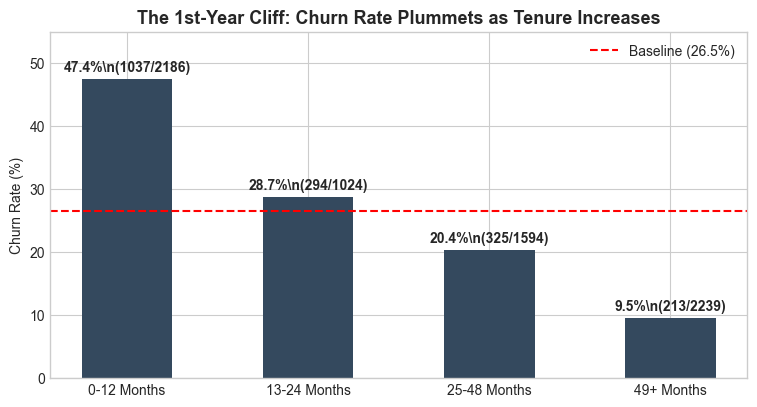

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(tenure_stats.index, tenure_stats['ChurnRate'], color='#34495e', width=0.5)
ax.axhline(churn_rate, color='red', linestyle='--', label=f'Baseline ({churn_rate:.1f}%)')
ax.set_title("The 1st-Year Cliff: Churn Rate Plummets as Tenure Increases", fontsize=13, weight='bold')
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 55)
ax.legend()
for b, (_, row) in zip(bars, tenure_stats.iterrows()):
    ax.text(b.get_x() + b.get_width()/2., b.get_height() + 1.2, f"{b.get_height():.1f}%\\n({int(row['Churned'])}/{int(row['Total'])})", ha='center', weight='bold')
plt.show()


## 5. Internet Service Type & Support Moat
Investigate why Fiber Optic customers have high churn and how Tech Support mitigates it.


In [8]:
internet_summary = df.groupby(['InternetService', 'TechSupport']).agg(
    Total=('customerID', 'count'),
    Churned=('ChurnFlag', 'sum'),
    ChurnRate=('ChurnFlag', lambda s: s.mean() * 100)
).reset_index()
internet_summary


,InternetService,TechSupport,Total,Churned,ChurnRate
0,DSL,No,1243,345,27.76
1,DSL,Yes,1178,114,9.68
2,Fiber optic,No,2230,1101,49.37
3,Fiber optic,Yes,866,196,22.63
4,No,No internet service,1526,113,7.40


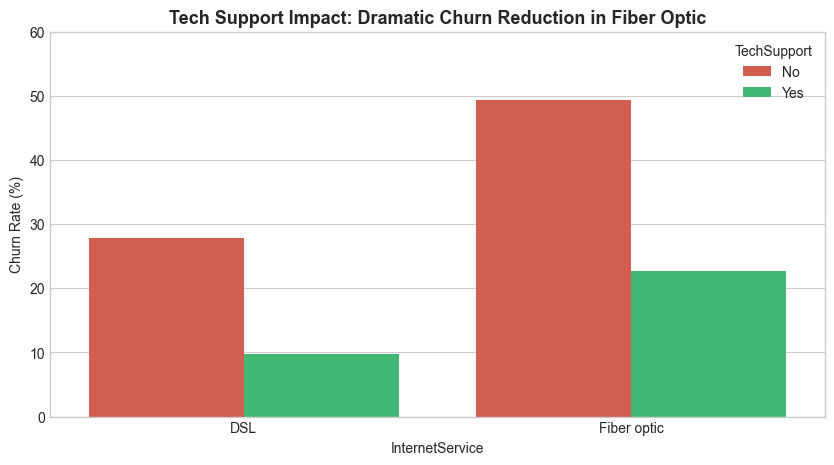

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=internet_summary[internet_summary['InternetService'] != 'No'],
            x='InternetService', y='ChurnRate', hue='TechSupport', palette=['#e74c3c', '#2ecc71'])
ax.set_title("Tech Support Impact: Dramatic Churn Reduction in Fiber Optic", fontsize=13, weight='bold')
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 60)
plt.show()


## 6. Payment Method & Billing Friction

In [10]:
pm_stats = df.groupby(['PaymentCategory', 'PaymentMethod']).agg(
    Total=('customerID', 'count'),
    Churned=('ChurnFlag', 'sum'),
    ChurnRate=('ChurnFlag', lambda s: s.mean() * 100)
).reset_index()
pm_stats


,PaymentCategory,PaymentMethod,Total,Churned,ChurnRate
0,Automatic,Bank transfer (automatic),1544,258,16.71
1,Automatic,Credit card (automatic),1522,232,15.24
2,Manual,Electronic check,2365,1071,45.29
3,Manual,Mailed check,1612,308,19.11


## 7. Revenue Analysis: Monthly Charges & Revenue at Risk

In [11]:
print(f"Average Monthly Charge (Retained): ${df[df['ChurnFlag'] == 0]['MonthlyCharges'].mean():.2f}")
print(f"Average Monthly Charge (Churned):  ${df[df['ChurnFlag'] == 1]['MonthlyCharges'].mean():.2f}")

monthly_rev_at_risk = df[df['ChurnFlag'] == 1]['MonthlyCharges'].sum()
annual_rev_at_risk = monthly_rev_at_risk * 12
print(f"Total Monthly Recurring Revenue at Risk: ${monthly_rev_at_risk:,.2f}")
print(f"Total Annualized Revenue at Risk:        ${annual_rev_at_risk:,.2f}")


Average Monthly Charge (Retained): $61.27
Average Monthly Charge (Churned):  $74.44
Total Monthly Recurring Revenue at Risk: $139,130.85
Total Annualized Revenue at Risk:        $1,669,570.20
